# Entrega Final — Predicción de abandono (churn) de estudiantes de Platzi
**Alumno:** Kevin Larguia
**Curso:** Data Science II — Coderhouse
**Fecha:** Noviembre 2026

Esta entrega retoma el proyecto anterior (Platzi Churn, donde comparé un Árbol de Decisión contra KNN) y lo lleva a un flujo completo de Machine Learning:

| En la entrega anterior | En esta entrega |
|---|---|
| Un solo split train/test | **Validación cruzada estratificada (5 folds)** |
| Hiperparámetros elegidos a mano (`max_depth=5`, `k=5`) | **GridSearchCV y RandomizedSearchCV** |
| 2 modelos | **4 modelos** (Árbol, KNN, Random Forest, XGBoost) |
| Transformaciones paso a paso | **Pipeline + ColumnTransformer** (sin leakage dentro de la validación cruzada) |
| Umbral de 0.5 fijo | **Umbral ajustado al objetivo de negocio** |
| Importancia de variables solo por ANOVA F | **Interpretación con SHAP** |

## 1. Abstracto: motivación y audiencia

**Motivación.** En una plataforma de suscripción como Platzi, cada estudiante que cancela es ingreso recurrente que se pierde, y conseguir un estudiante nuevo cuesta bastante más que retener a uno que ya está. En el dataset, **casi 4 de cada 10 estudiantes (36.8%) abandonan**. Si pudiéramos saber *antes* quién está en riesgo, el equipo de retención podría actuar a tiempo (un descuento, un recordatorio, un tutor, ayuda con el pago) en lugar de enterarse cuando el estudiante ya se fue.

**Audiencia.**
- **Equipo de Retención / Customer Success:** recibe una lista priorizada de estudiantes en riesgo para contactar.
- **Marketing y Producto:** entienden *qué comportamientos* anticipan el abandono (inactividad, problemas de pago, tipo de plan) y pueden diseñar acciones preventivas.
- **Dirección / Finanzas:** pueden estimar cuánto ingreso está en riesgo y cuánto se podría recuperar.

## 2. Problema a resolver

**Pregunta principal (clasificación binaria):** *¿Podemos predecir si un estudiante va a abandonar su suscripción (`churn = 1`) a partir de sus datos de perfil, uso de la plataforma, pagos e interacción con los cursos?*

**Preguntas secundarias:**
1. ¿Qué variables pesan más en el riesgo de abandono?
2. ¿Un modelo de ensamble (Random Forest / XGBoost) mejora a los modelos simples que usé en la entrega anterior?
3. Si el equipo de retención solo puede contactar a una parte de los estudiantes, ¿qué porcentaje de los que se van logramos detectar?

**Métrica principal:** **ROC-AUC**, porque el dataset está desbalanceado (36.8% / 63.2%) y porque no depende de un umbral fijo: mide qué tan bien el modelo *ordena* a los estudiantes de mayor a menor riesgo, que es justamente lo que necesita el equipo de retención. Como métricas de apoyo uso **recall** (de los que se van, cuántos detectamos), **precision** y **F1**.

---
## 3. Librerías

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score,
                             f1_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve)
from scipy.stats import randint, uniform
from xgboost import XGBClassifier
import shap

SEED = 42
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 80)

---
## 4. Carga de datos

Uso los mismos 3 archivos de la entrega anterior:
- `platzi_churn.csv`: una fila por estudiante (perfil, plan, pagos, uso de la plataforma) + la variable objetivo `churn`.
- `platzi_courses.csv`: catálogo de cursos (escuela, dificultad, popularidad, rating).
- `platzi_interactions.csv`: una fila por cada estudiante–curso (progreso, si lo completó, rating que puso, fechas).

In [2]:
df = pd.read_csv('platzi_churn.csv')
cursos = pd.read_csv('platzi_courses.csv')
inter = pd.read_csv('platzi_interactions.csv')

for nombre, d in [('estudiantes', df), ('cursos', cursos), ('interacciones', inter)]:
    print(f'{nombre:14s} -> {d.shape[0]:>6} filas x {d.shape[1]:>2} columnas')

estudiantes    ->   4891 filas x 58 columnas
cursos         ->     83 filas x  8 columnas
interacciones  ->  44864 filas x  7 columnas


In [3]:
df.head()

,student_id,pais,edad,genero,plan,escuela_principal,dispositivo_principal,objetivo_estudiante,nivel_educativo,experiencia_tech_anios,meses_suscrito,tipo_pago,dias_para_renovacion,intentos_pago_fallidos,fecha_registro,dias_en_gratuito_antes_pago,cursos_inscritos,tasa_completado,cursos_completados,certificados_obtenidos,rutas_inscritas,rutas_completadas,examenes_ruta_aprobados,interes_Prog,interes_DataSci,interes_Web,interes_Ingles,interes_Marketing,interes_Diseno,interes_Gestion,interes_SoftSkills,interes_Cloud,interes_Otros,dias_desde_ultimo_login,dias_desde_ultima_clase,sesiones_ultimo_mes,horas_vistas_total,horas_vistas_ultimo_mes,promedio_clases_semana,horas_semana_1,horas_semana_2,horas_semana_3,horas_semana_4,variacion_sesiones_vs_mes_anterior,racha_dias_maxima,racha_dias_actual,liveclasses_asistidas,hora_pico_uso,preguntas_en_foro,respuestas_en_foro,upvotes_recibidos,tutoriales_publicados,platzi_rank,nivel_rewards,tickets_soporte,dias_resolucion_promedio,nps_score,churn
0,PLZ-00001,Colombia,27,Femenino,Expert,Escuela de Programacion y Software,Mobile,Ascender en trabajo actual,Secundaria,3,12,Anual,238.0,0,2023-03-29,21,8,0.10,0,0,1,0,0,0.41,0.18,0.12,0.16,0.14,0.29,0.20,0.48,0.10,0.16,25,35,8,35,15,3.8,3.3,2.4,3.5,3.4,-0.1,3,0,6,14,1,6,13,0,285,Estandar,0,0.0,9.0,0
1,PLZ-00002,Uruguay,23,Femenino,Expert Duo,Escuela de Videojuegos,Mobile,Conseguir empleo tech,Tecnico,0,8,Anual,349.0,0,2022-06-20,55,11,0.20,2,1,0,0,0,0.16,0.59,0.52,0.08,0.54,0.34,0.23,0.19,0.21,0.36,1,13,11,60,12,3.0,3.8,3.1,2.7,3.4,2.0,7,2,3,13,3,3,5,0,372,Estandar,0,0.0,6.0,0
2,PLZ-00003,Perú,23,Masculino,Expert,Escuela de Videojuegos,Desktop,Conseguir empleo tech,Universitario en curso,3,1,Cuotas x4,247.0,0,2024-02-01,75,5,0.62,3,2,1,0,0,0.22,0.03,0.18,0.16,0.07,0.11,0.17,0.19,0.07,0.30,12,18,10,56,16,4.0,5.2,3.5,4.5,3.1,-1.7,5,0,1,17,3,1,0,0,102,Estandar,1,3.2,2.0,0
3,PLZ-00004,Argentina,18,Femenino,Expert Duo,Escuela de Videojuegos,Desktop,Conseguir empleo tech,Tecnico,3,11,Cuotas x4,159.0,0,2022-12-05,65,12,0.48,5,4,3,1,0,0.23,0.23,0.34,0.10,0.14,0.02,0.24,0.13,0.34,0.11,4,7,15,84,5,1.2,1.8,1.7,1.9,1.8,-0.8,1,0,5,11,2,5,12,0,801,Estandar,1,4.5,NaN,0
4,PLZ-00005,México,23,Femenino,Gratuito,Escuela de Desarrollo Web,Mobile,Freelance / proyectos propios,Tecnico,0,5,Sin_suscripcion,-1.0,0,2022-02-28,31,2,0.48,0,0,1,0,0,0.03,0.57,0.53,0.19,0.28,0.39,0.22,0.06,0.33,0.15,2,4,5,7,7,1.8,1.0,1.3,1.4,2.6,3.1,7,0,0,7,4,4,10,0,201,Estandar,0,0.0,9.0,0


---
## 5. Breve análisis exploratorio (EDA)

El EDA completo está en la entrega anterior; acá repaso lo necesario para tomar decisiones de modelado.

### 5.1 Metadata: tipos de variables

In [4]:
tipos = df.dtypes.astype(str).replace({'object': 'categorica (texto)', 'str': 'categorica (texto)',
                                        'int64': 'numerica entera', 'float64': 'numerica decimal'})
print(tipos.value_counts().to_string())
print()
print('Variables categoricas:', df.select_dtypes('object').columns.tolist())
print('(student_id es un identificador y fecha_registro una fecha en texto: no entran al modelo tal cual)')

numerica entera       27
numerica decimal      20
categorica (texto)    11

Variables categoricas: ['student_id', 'pais', 'genero', 'plan', 'escuela_principal', 'dispositivo_principal', 'objetivo_estudiante', 'nivel_educativo', 'tipo_pago', 'fecha_registro', 'nivel_rewards']
(student_id es un identificador y fecha_registro una fecha en texto: no entran al modelo tal cual)


### 5.2 Variable objetivo

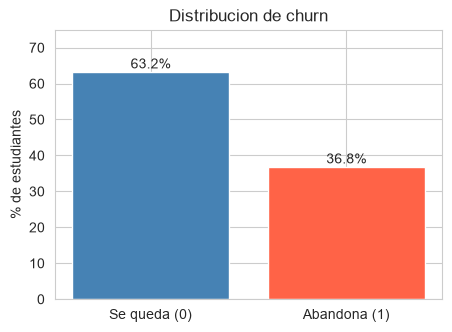

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.5))
pct = df['churn'].value_counts(normalize=True).sort_index() * 100
ax.bar(['Se queda (0)', 'Abandona (1)'], pct.values, color=['steelblue', 'tomato'])
for i, v in enumerate(pct.values):
    ax.text(i, v + 1, f'{v:.1f}%', ha='center')
ax.set_ylabel('% de estudiantes'); ax.set_ylim(0, 75)
ax.set_title('Distribucion de churn')
plt.show()

Desbalance moderado (36.8% churn). Por eso: split **estratificado**, validación cruzada **estratificada**, y métricas que no se engañan con el desbalance (AUC, recall, F1) en vez de accuracy.

### 5.3 Valores faltantes

In [6]:
faltantes = pd.DataFrame({
    'archivo': ['churn'] * df.shape[1] + ['interactions'] * inter.shape[1],
    'columna': list(df.columns) + list(inter.columns),
    'nulos': list(df.isnull().sum()) + list(inter.isnull().sum()),
})
faltantes['%'] = np.where(faltantes['archivo'] == 'churn',
                          faltantes['nulos'] / len(df) * 100,
                          faltantes['nulos'] / len(inter) * 100).round(1)
faltantes[faltantes['nulos'] > 0]

,archivo,columna,nulos,%
56,churn,nps_score,230,4.7
61,interactions,rating,24985,55.7


In [7]:
# ¿El hecho de NO responder la encuesta NPS se relaciona con el churn?
df.assign(respondio_nps=df['nps_score'].notna()).groupby('respondio_nps')['churn'].agg(['mean', 'count']).round(3)

,mean,count
respondio_nps,,
False,0.374,230
True,0.368,4661


- `nps_score` (4.7% nulos): estudiantes que no respondieron la encuesta. La tasa de churn es casi igual entre los que respondieron y los que no, así que el faltante parece **aleatorio** → lo imputo con la **mediana** (dentro del pipeline, aprendida solo con train).
- `rating` en interactions (55.7% nulos): la mayoría no califica los cursos. No lo imputo a nivel interacción; al resumir por estudiante queda un promedio que puede ser nulo y también se imputa con la mediana.

### 5.4 Variables numéricas más relacionadas con el churn

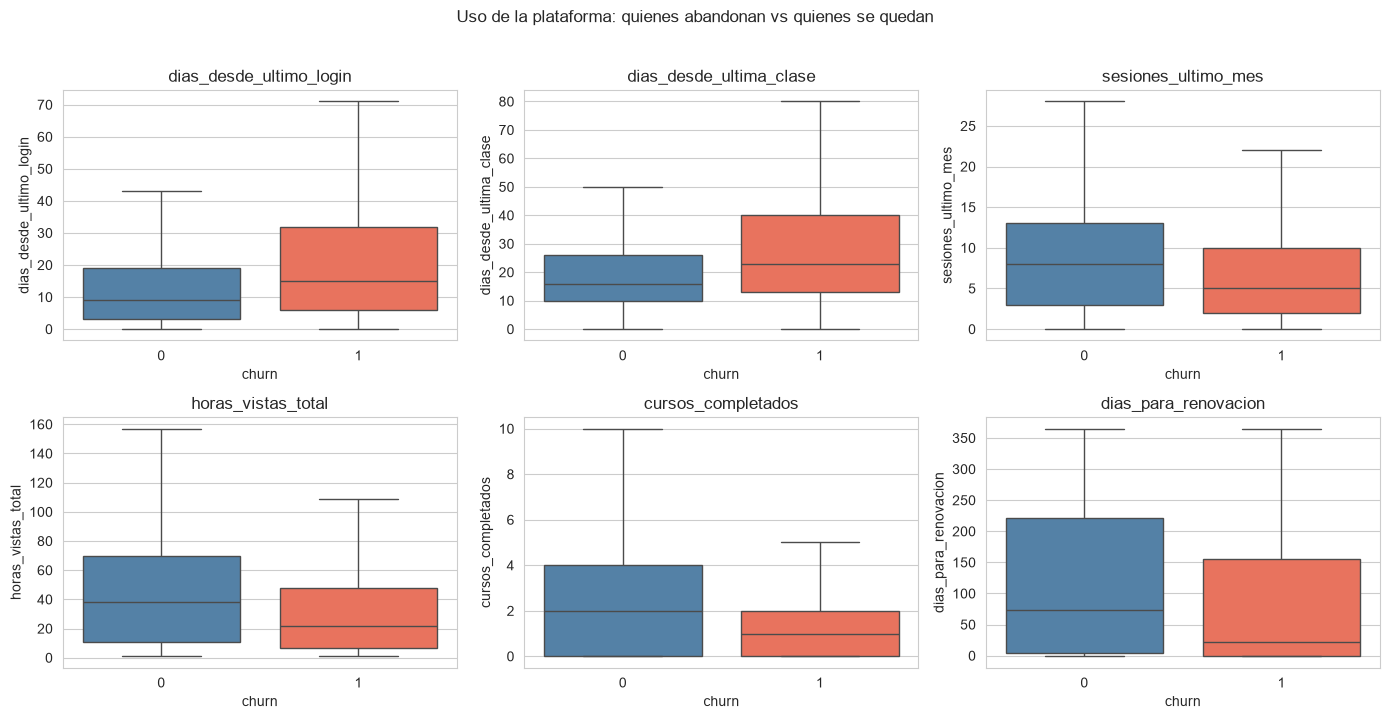

In [8]:
cols_clave = ['dias_desde_ultimo_login', 'dias_desde_ultima_clase', 'sesiones_ultimo_mes',
              'horas_vistas_total', 'cursos_completados', 'dias_para_renovacion']
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(ejes.flatten(), cols_clave):
    sns.boxplot(x='churn', y=col, data=df, hue='churn', palette=['steelblue', 'tomato'],
                legend=False, ax=ax, showfliers=False)
    ax.set_title(col); ax.set_xlabel('churn')
plt.suptitle('Uso de la plataforma: quienes abandonan vs quienes se quedan', y=1.02)
plt.tight_layout(); plt.show()

Los que abandonan pasan **más días sin entrar** y tienen **menos sesiones, horas y cursos completados**. También tienen menos días para la renovación (están más cerca del momento de decidir si pagan de nuevo).

### 5.5 Variables categóricas: plan y forma de pago

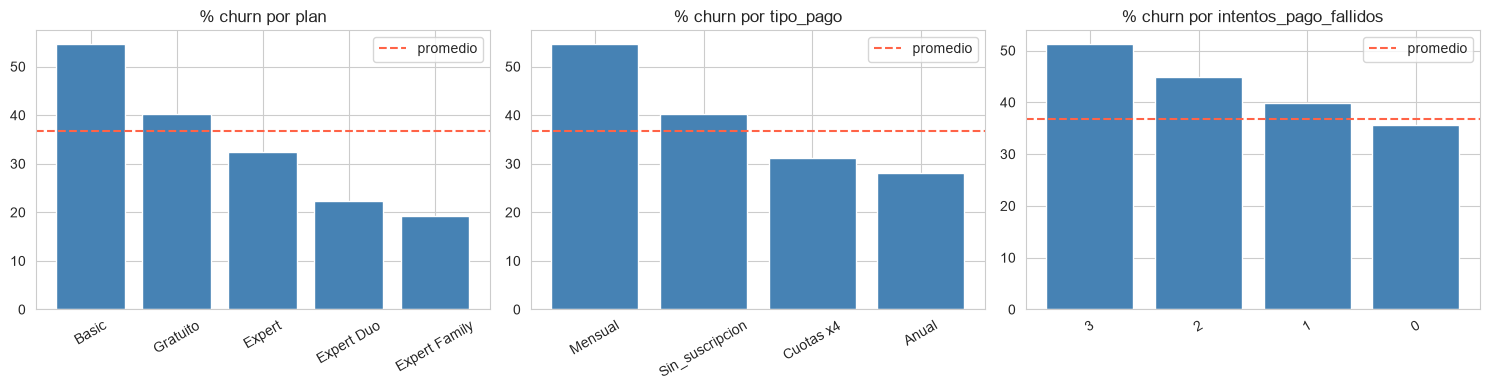

In [9]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(ejes, ['plan', 'tipo_pago', 'intentos_pago_fallidos']):
    tasa = df.groupby(col)['churn'].mean().sort_values(ascending=False) * 100
    ax.bar(tasa.index.astype(str), tasa.values, color='steelblue')
    ax.axhline(df['churn'].mean() * 100, color='tomato', ls='--', label='promedio')
    ax.set_title(f'% churn por {col}'); ax.tick_params(axis='x', rotation=30); ax.legend()
plt.tight_layout(); plt.show()

- El plan **Basic** (mensual) tiene mucho más churn que los planes anuales/familiares.
- Cada intento de pago fallido sube la tasa de churn (de ~36% con 0 intentos a ~51% con 3).

### 5.6 Conclusiones del EDA para el modelado
- Ninguna variable por sí sola separa bien a los dos grupos (correlaciones entre -0.20 y 0.20): el problema es **multivariado** y hay que combinar varias señales → buen caso para modelos de ensamble.
- Hay variables con escalas muy distintas (`edad` vs `platzi_rank`) → **estandarizar** (sobre todo para KNN).
- Hay 10 variables categóricas → **One-Hot Encoding**.

---
## 6. Ingeniería de atributos

### 6.1 Variables nuevas a partir de `courses` e `interactions`
Igual que en la entrega anterior, cruzo interacciones con el catálogo de cursos y resumo por estudiante. Además, ahora **aprovecho las fechas** de las interacciones, que antes no usaba.

In [10]:
inter['date_started'] = pd.to_datetime(inter['date_started'])
inter['date_last_access'] = pd.to_datetime(inter['date_last_access'])
FECHA_CORTE = inter['date_last_access'].max()   # fecha de la "foto" de los datos
print('Fecha de corte de los datos:', FECHA_CORTE.date())

inter_cursos = inter.merge(cursos, on='course_id', how='left')
inter_cursos['dificultad_num'] = inter_cursos['difficulty'].map({'Basico': 1, 'Intermedio': 2, 'Avanzado': 3})

resumen = inter_cursos.groupby('student_id').agg(
    cantidad_interacciones=('course_id', 'count'),
    promedio_progreso=('progress', 'mean'),
    promedio_rating_dado=('rating', 'mean'),
    cantidad_completados=('completed', 'sum'),
    promedio_dificultad=('dificultad_num', 'mean'),
    promedio_popularidad_cursos=('popularity', 'mean'),
    escuelas_distintas=('school', 'nunique'),
    ultimo_acceso_curso=('date_last_access', 'max'),
    primer_curso=('date_started', 'min'),
).reset_index()

# Nuevas: recencia y antigüedad en cursos
resumen['dias_sin_acceder_a_cursos'] = (FECHA_CORTE - resumen['ultimo_acceso_curso']).dt.days
resumen['dias_desde_primer_curso'] = (FECHA_CORTE - resumen['primer_curso']).dt.days
resumen = resumen.drop(columns=['ultimo_acceso_curso', 'primer_curso'])

df = df.merge(resumen, on='student_id', how='left')
print(df.shape)

Fecha de corte de los datos: 2026-05-18
(4891, 67)


### 6.2 Variables nuevas a partir de las columnas existentes

In [11]:
# Antigüedad como cliente (en días) a partir de la fecha de registro (texto -> fecha -> número)
df['antiguedad_dias'] = (FECHA_CORTE - pd.to_datetime(df['fecha_registro'])).dt.days

# Tendencia de uso en el último mes: ¿las horas de la semana 4 son más o menos que las de la semana 1?
df['tendencia_horas_mes'] = df['horas_semana_4'] - df['horas_semana_1']

# Qué parte de todo lo que vio lo vio en el último mes (actividad reciente relativa)
df['ratio_horas_ultimo_mes'] = df['horas_vistas_ultimo_mes'] / (df['horas_vistas_total'] + 1)

# Marca binaria: tuvo al menos un pago fallido
df['tuvo_pago_fallido'] = (df['intentos_pago_fallidos'] > 0).astype(int)

# Cursos terminados sobre cursos inscritos en interactions
df['ratio_completados_inter'] = df['cantidad_completados'] / df['cantidad_interacciones'].replace(0, np.nan)

nuevas = ['dias_sin_acceder_a_cursos', 'dias_desde_primer_curso', 'antiguedad_dias',
          'tendencia_horas_mes', 'ratio_horas_ultimo_mes', 'tuvo_pago_fallido', 'ratio_completados_inter']
df[nuevas + ['churn']].corr()['churn'].drop('churn').sort_values().round(3)

ratio_completados_inter     -0.094
dias_desde_primer_curso     -0.051
tendencia_horas_mes         -0.001
ratio_horas_ultimo_mes       0.011
antiguedad_dias              0.025
tuvo_pago_fallido            0.056
dias_sin_acceder_a_cursos    0.199
Name: churn, dtype: float64

La nueva variable más prometedora es **`dias_sin_acceder_a_cursos`** (correlación punto-biserial ≈ 0.20, al nivel de `dias_desde_ultimo_login`, la mejor variable del dataset original). Las demás aportan poco de forma individual, pero las dejo: los modelos de árboles pueden encontrar combinaciones útiles, y en la sección 9 compruebo con validación cruzada si en conjunto suman o no.

> Recordatorio: la correlación con una variable binaria es punto-biserial; la uso solo como un ordenamiento rápido, no como prueba de importancia.

### 6.3 Separación train / test (antes de cualquier transformación)
Separo un 20% como **test final**, que no se toca hasta el final. Todo el ajuste de hiperparámetros y la comparación de modelos se hace con **validación cruzada sobre el 80% de train**.

In [12]:
X = df.drop(columns=['student_id', 'fecha_registro', 'churn'])
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print('train:', X_train.shape, '| test:', X_test.shape)
print(f'% churn train: {y_train.mean():.3f} | test: {y_test.mean():.3f}')

train: (3912, 69) | test: (979, 69)
% churn train: 0.368 | test: 0.368


### 6.4 Transformaciones: imputación, encoding y estandarización (dentro de un Pipeline)

En la entrega anterior aprendí que **todo lo que hace `.fit()` tiene que aprender solo del train**. Con validación cruzada esto es todavía más importante: en cada fold, la parte de validación tampoco puede "filtrarse" al imputer, al encoder o al scaler. La forma correcta de hacerlo es meter las transformaciones en un **`Pipeline`**: así `cross_validate` y `GridSearchCV` vuelven a ajustar todo dentro de cada fold automáticamente.

- **Numéricas:** imputación con mediana + `StandardScaler` (media 0, desvío 1).
- **Categóricas:** imputación con la moda + `OneHotEncoder` (`handle_unknown='ignore'` por si aparece una categoría nueva).

In [13]:
cat_cols = X_train.select_dtypes(include='object').columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]
print(len(num_cols), 'numericas |', len(cat_cols), 'categoricas')

preprocesador = ColumnTransformer([
    ('num', Pipeline([('imputar', SimpleImputer(strategy='median')),
                      ('escalar', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols),
])

# Muestra de cómo queda la matriz (ajustando SOLO con train)
X_train_tr = preprocesador.fit_transform(X_train)
print('Columnas despues del encoding:', X_train_tr.shape[1])
print('Media de las numericas escaladas (≈0):', X_train_tr[:, :len(num_cols)].mean().round(3))
print('Desvio de las numericas escaladas (≈1):', X_train_tr[:, :len(num_cols)].std().round(3))

60 numericas | 9 categoricas
Columnas despues del encoding: 121
Media de las numericas escaladas (≈0): 0.0
Desvio de las numericas escaladas (≈1): 1.0


---
## 7. Entrenamiento y testeo con validación cruzada (modelos base)

Entreno 4 modelos con hiperparámetros por defecto (o los que usé en la entrega anterior) y los comparo con **validación cruzada estratificada de 5 folds** sobre train. Esto me da una línea de base antes de optimizar.

| Modelo | Por qué lo incluyo |
|---|---|
| **Árbol de Decisión** | Modelo final de la entrega anterior; interpretable. |
| **KNN** | El otro modelo de la entrega anterior (sobreajustaba con k=5). |
| **Random Forest** | Ensamble *bagging*: promedia muchos árboles → reduce el sobreajuste. |
| **XGBoost** | Ensamble *boosting*: cada árbol corrige los errores del anterior; suele rendir muy bien en datos tabulares. |

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metricas_cv = {'auc': 'roc_auc', 'recall': 'recall', 'precision': 'precision', 'f1': 'f1', 'accuracy': 'accuracy'}

modelos_base = {
    'Arbol de Decision': DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'XGBoost': XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='logloss'),
}

def evaluar_cv(modelo):
    pipe = Pipeline([('prep', preprocesador), ('modelo', modelo)])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metricas_cv, return_train_score=True, n_jobs=-1)
    return r

filas = []
for nombre, modelo in modelos_base.items():
    r = evaluar_cv(modelo)
    filas.append({'modelo': nombre,
                  'AUC train': r['train_auc'].mean(), 'AUC CV': r['test_auc'].mean(), 'AUC CV (desvio)': r['test_auc'].std(),
                  'recall CV': r['test_recall'].mean(), 'f1 CV': r['test_f1'].mean()})
base = pd.DataFrame(filas).set_index('modelo').round(3)
base

,AUC train,AUC CV,AUC CV (desvio),recall CV,f1 CV
modelo,,,,,
Arbol de Decision,0.714,0.614,0.008,0.232,0.324
KNN,0.793,0.578,0.021,0.369,0.407
Random Forest,1.000,0.651,0.011,0.270,0.374
XGBoost,1.000,0.607,0.007,0.346,0.407


Lectura de la línea de base:
- **Random Forest y XGBoost con hiperparámetros por defecto sobreajustan muchísimo** (AUC en train = 1.0 contra 0.65 y 0.61 en validación): se aprenden de memoria el train.
- **KNN** con k=5 tiene el mismo problema que vi en la entrega anterior (0.79 en train vs 0.58 en validación).
- El **recall** de todos es bajo con el umbral de 0.5: se les escapan la mayoría de los estudiantes que abandonan.

Esto justifica el siguiente paso: **optimizar hiperparámetros** para controlar la complejidad de cada modelo.

---
## 8. Optimización de hiperparámetros

Uso dos técnicas, siempre con la misma validación cruzada de 5 folds y **optimizando AUC**:
- **GridSearchCV** (prueba todas las combinaciones) para Árbol y KNN, que tienen pocos hiperparámetros.
- **RandomizedSearchCV** (prueba combinaciones al azar dentro de rangos) para Random Forest y XGBoost, que tienen muchos y una grilla completa sería muy lenta.

En todos los casos incluyo hiperparámetros para el **desbalance** (`class_weight='balanced'` o `scale_pos_weight`), que hacen que el modelo le dé más peso a la clase minoritaria (churn).

Para KNN agrego también un paso de **feature selection** (`SelectKBest` con ANOVA F, igual que en la entrega anterior) y dejo que la búsqueda elija cuántas variables usar: KNN sufre mucho con muchas dimensiones, porque las distancias pierden sentido.

In [15]:
def pipe(modelo, seleccion=False):
    pasos = [('prep', preprocesador)]
    if seleccion:
        pasos.append(('seleccion', SelectKBest(f_classif)))
    pasos.append(('modelo', modelo))
    return Pipeline(pasos)

ratio_desbalance = (y_train == 0).sum() / (y_train == 1).sum()

busquedas = {
    'Arbol de Decision': GridSearchCV(
        pipe(DecisionTreeClassifier(random_state=SEED)),
        {'modelo__max_depth': [3, 4, 5, 6, 8],
         'modelo__min_samples_leaf': [10, 30, 60, 100],
         'modelo__criterion': ['gini', 'entropy'],
         'modelo__class_weight': [None, 'balanced']},
        cv=cv, scoring='roc_auc', n_jobs=-1, return_train_score=True),

    'KNN': GridSearchCV(
        pipe(KNeighborsClassifier(), seleccion=True),
        {'seleccion__k': [10, 15, 25, 40],
         'modelo__n_neighbors': [25, 50, 100, 150, 200],
         'modelo__weights': ['uniform', 'distance']},
        cv=cv, scoring='roc_auc', n_jobs=-1, return_train_score=True),

    'Random Forest': RandomizedSearchCV(
        pipe(RandomForestClassifier(random_state=SEED, n_jobs=-1)),
        {'modelo__n_estimators': randint(200, 600),
         'modelo__max_depth': [4, 6, 8, 10, 14, None],
         'modelo__min_samples_leaf': randint(5, 60),
         'modelo__max_features': ['sqrt', 'log2', 0.3, 0.5],
         'modelo__class_weight': [None, 'balanced', 'balanced_subsample']},
        n_iter=30, cv=cv, scoring='roc_auc', n_jobs=-1, random_state=SEED, return_train_score=True),

    'XGBoost': RandomizedSearchCV(
        pipe(XGBClassifier(random_state=SEED, n_jobs=1, eval_metric='logloss')),
        {'modelo__n_estimators': randint(100, 600),
         'modelo__learning_rate': uniform(0.01, 0.15),
         'modelo__max_depth': randint(2, 6),
         'modelo__min_child_weight': randint(1, 20),
         'modelo__subsample': uniform(0.6, 0.4),
         'modelo__colsample_bytree': uniform(0.4, 0.6),
         'modelo__reg_lambda': uniform(0.5, 10),
         'modelo__scale_pos_weight': [1, ratio_desbalance]},
        n_iter=40, cv=cv, scoring='roc_auc', n_jobs=-1, random_state=SEED, return_train_score=True),
}

for nombre, busqueda in busquedas.items():
    busqueda.fit(X_train, y_train)
    print(f'{nombre:18s} mejor AUC CV = {busqueda.best_score_:.4f}')

Arbol de Decision  mejor AUC CV = 0.6333


KNN                mejor AUC CV = 0.6592


Random Forest      mejor AUC CV = 0.6624


XGBoost            mejor AUC CV = 0.6595


In [16]:
for nombre, busqueda in busquedas.items():
    params = {k.replace('modelo__', '').replace('seleccion__', 'seleccion_'): (round(v, 3) if isinstance(v, float) else v)
              for k, v in busqueda.best_params_.items()}
    print(f'\n{nombre}:\n  {params}')


Arbol de Decision:
  {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 30}

KNN:
  {'n_neighbors': 200, 'weights': 'distance', 'seleccion_k': 15}

Random Forest:
  {'class_weight': None, 'max_depth': 6, 'max_features': 0.3, 'min_samples_leaf': 57, 'n_estimators': 479}

XGBoost:
  {'colsample_bytree': np.float64(0.537), 'learning_rate': np.float64(0.022), 'max_depth': 4, 'min_child_weight': 19, 'n_estimators': 185, 'reg_lambda': np.float64(9.305), 'scale_pos_weight': np.float64(1.719), 'subsample': np.float64(0.923)}


### 8.1 Comparación antes vs después de optimizar

In [17]:
filas = []
for nombre, busqueda in busquedas.items():
    i = busqueda.best_index_
    res = busqueda.cv_results_
    filas.append({'modelo': nombre,
                  'AUC CV base': base.loc[nombre, 'AUC CV'],
                  'AUC CV optimizado': res['mean_test_score'][i],
                  'desvio CV': res['std_test_score'][i],
                  'AUC train optimizado': res['mean_train_score'][i]})
comparacion = pd.DataFrame(filas).set_index('modelo')
comparacion['brecha train-CV'] = comparacion['AUC train optimizado'] - comparacion['AUC CV optimizado']
comparacion = comparacion.round(3).sort_values('AUC CV optimizado', ascending=False)
comparacion

,AUC CV base,AUC CV optimizado,desvio CV,AUC train optimizado,brecha train-CV
modelo,,,,,
Random Forest,0.651,0.662,0.007,0.748,0.086
KNN,0.578,0.659,0.007,1.000,0.341
XGBoost,0.607,0.659,0.008,0.792,0.133
Arbol de Decision,0.614,0.633,0.007,0.660,0.027


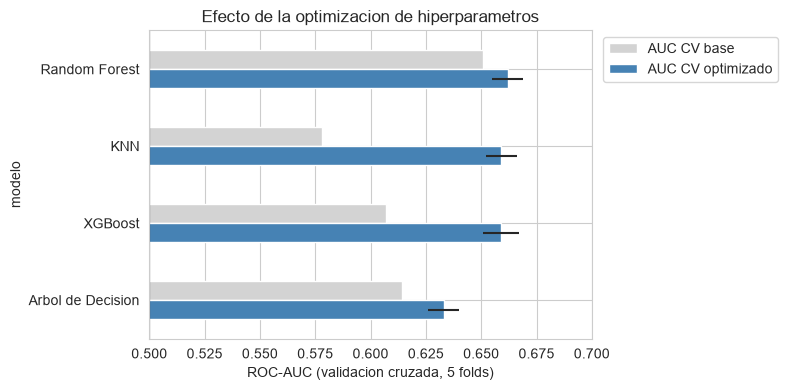

In [18]:
ax = comparacion[['AUC CV base', 'AUC CV optimizado']].plot(kind='barh', figsize=(8, 4),
                                                           color=['lightgray', 'steelblue'],
                                                           xerr=[np.zeros(len(comparacion)), comparacion['desvio CV']])
ax.set_xlim(0.5, 0.7); ax.axvline(0.5, color='black', lw=0.8)
ax.set_xlabel('ROC-AUC (validacion cruzada, 5 folds)')
ax.set_title('Efecto de la optimizacion de hiperparametros')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
ax.invert_yaxis(); plt.tight_layout(); plt.show()

- La optimización **mejora a los 4 modelos**. La mejora más grande la tienen **KNN** (0.578 → 0.659) y **XGBoost** (0.607 → 0.659).
- La búsqueda eligió modelos **menos complejos**: árbol de profundidad 3, KNN con 200 vecinos y solo 15 variables, Random Forest con hojas de al menos ~57 estudiantes, XGBoost con árboles chicos, learning rate bajo y regularización fuerte. Por eso la **brecha train–CV** de los ensambles cae de ≈0.35–0.39 (por defecto) a 0.09 (RF) y 0.13 (XGBoost).
- *Ojo con KNN:* con `weights='distance'` el AUC de train siempre da 1.0, porque cada estudiante de train es su propio vecino a distancia 0. Esa brecha no indica sobreajuste en este caso; lo que vale para KNN es el AUC de validación.
- **Random Forest** queda primero (0.662), con KNN y XGBoost prácticamente empatados detrás (0.659). Las diferencias entre los tres son del orden del desvío entre folds (≈0.007); el Árbol de Decisión queda claramente por debajo.

---
## 9. ¿Las variables nuevas aportan? (validación cruzada con y sin ingeniería de atributos)
Uso el mejor XGBoost encontrado y comparo el AUC de validación cruzada usando solo las columnas originales vs. todas.

In [19]:
from sklearn.base import clone

xgb_mejor_params = {k.replace('modelo__', ''): v for k, v in busquedas['XGBoost'].best_params_.items()}

def auc_cv_con_columnas(columnas):
    cats = [c for c in columnas if c in cat_cols]
    nums = [c for c in columnas if c not in cats]
    prep = ColumnTransformer([
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler())]), nums),
        ('cat', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cats)])
    p = Pipeline([('prep', prep), ('modelo', XGBClassifier(random_state=SEED, n_jobs=1, eval_metric='logloss', **xgb_mejor_params))])
    r = cross_validate(p, X_train[columnas], y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    return r['test_score'].mean(), r['test_score'].std()

originales = [c for c in X_train.columns if c in pd.read_csv('platzi_churn.csv', nrows=1).columns]
de_interactions = [c for c in resumen.columns if c != 'student_id']

escenarios = {
    'Solo platzi_churn (original)': originales,
    '+ resumen de interactions/courses': originales + de_interactions,
    '+ todas las variables nuevas': list(X_train.columns),
}
tabla_fe = pd.DataFrame({k: auc_cv_con_columnas(v) for k, v in escenarios.items()}, index=['AUC CV', 'desvio']).T.round(4)
tabla_fe

,AUC CV,desvio
Solo platzi_churn (original),0.6581,0.0051
+ resumen de interactions/courses,0.6578,0.0071
+ todas las variables nuevas,0.6595,0.0077


Conclusión honesta: las variables nuevas **suman muy poco** en AUC (las diferencias son del orden del desvío entre folds). La señal principal ya estaba en las columnas de uso y pagos del archivo original. Igualmente mantengo el set completo porque no empeora el modelo y algunas variables nuevas (como `dias_sin_acceder_a_cursos`) aparecen entre las más importantes en el análisis SHAP, lo que ayuda a la interpretación.

---
## 10. Selección del modelo y evaluación final en test

**Criterio de selección:** el mayor **AUC promedio en validación cruzada** (no el de test, para no "elegir mirando el examen"), con una brecha train–CV razonable y desvío bajo entre folds. Recién después evalúo una sola vez en el test reservado.

Por AUC de validación gana **Random Forest**. Además, frente a sus competidores casi empatados tiene la menor brecha train–CV de los ensambles, y frente a KNN tiene la ventaja de ser explicable con SHAP (podemos decirle al negocio *por qué* un estudiante está en riesgo).

In [20]:
mejor_nombre = comparacion.index[0]
print('Modelo seleccionado por AUC en validacion cruzada:', mejor_nombre)

filas = []
probas_test = {}
for nombre, busqueda in busquedas.items():
    modelo = busqueda.best_estimator_     # ya re-entrenado con todo el train (refit=True)
    proba_tr = modelo.predict_proba(X_train)[:, 1]
    proba_te = modelo.predict_proba(X_test)[:, 1]
    probas_test[nombre] = proba_te
    pred_te = (proba_te >= 0.5).astype(int)
    filas.append({'modelo': nombre,
                  'AUC train': roc_auc_score(y_train, proba_tr),
                  'AUC CV': busqueda.best_score_,
                  'AUC test': roc_auc_score(y_test, proba_te),
                  'accuracy test': accuracy_score(y_test, pred_te),
                  'precision test': precision_score(y_test, pred_te, zero_division=0),
                  'recall test': recall_score(y_test, pred_te),
                  'f1 test': f1_score(y_test, pred_te)})
final = pd.DataFrame(filas).set_index('modelo').round(3).sort_values('AUC CV', ascending=False)
final

Modelo seleccionado por AUC en validacion cruzada: Random Forest


,AUC train,AUC CV,AUC test,accuracy test,precision test,recall test,f1 test
modelo,,,,,,,
Random Forest,0.744,0.662,0.655,0.679,0.660,0.264,0.377
KNN,1.000,0.659,0.657,0.672,0.640,0.247,0.357
XGBoost,0.777,0.659,0.663,0.622,0.488,0.547,0.516
Arbol de Decision,0.658,0.633,0.635,0.616,0.474,0.406,0.437


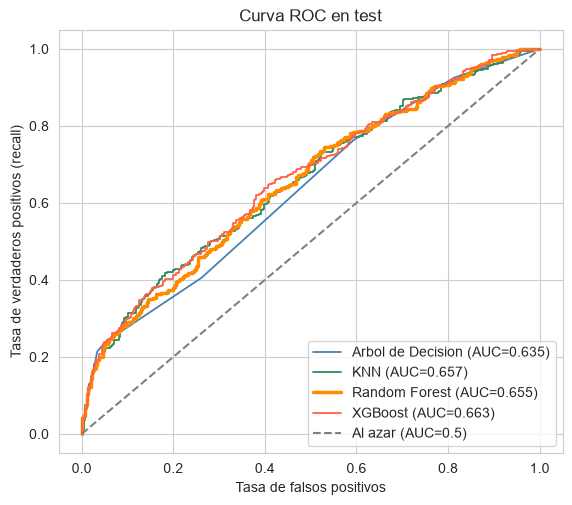

In [21]:
plt.figure(figsize=(6.5, 5.5))
colores = {'XGBoost': 'tomato', 'Random Forest': 'darkorange', 'Arbol de Decision': 'steelblue', 'KNN': 'seagreen'}
for nombre, proba in probas_test.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC={roc_auc_score(y_test, proba):.3f})', color=colores[nombre],
             lw=2.5 if nombre == mejor_nombre else 1.3)
plt.plot([0, 1], [0, 1], ls='--', color='gray', label='Al azar (AUC=0.5)')
plt.xlabel('Tasa de falsos positivos'); plt.ylabel('Tasa de verdaderos positivos (recall)')
plt.title('Curva ROC en test'); plt.legend(loc='lower right'); plt.show()

- El AUC de test de Random Forest (0.655) es casi igual al de validación cruzada (0.662) → **la estimación por CV era confiable y el modelo generaliza** (en la entrega anterior el árbol caía de 0.697 a 0.630).
- En test XGBoost da un poco más (0.663) y KNN parecido (0.657), pero esas diferencias están dentro del ruido; cambiar de modelo mirando el test sería justamente el error de "elegir mirando el examen". Todos los modelos optimizados superan al Árbol y al KNN de la entrega anterior (0.630 y 0.592 de AUC en test).
- El AUC está en torno a 0.65: el modelo es claramente mejor que el azar, pero el dataset tiene un **techo de predictibilidad moderado** (ningún modelo, hiperparámetro ni variable nueva lo superó de forma importante).
- Con el umbral de 0.5 el Random Forest es muy "conservador": precision 0.66 pero recall de solo 0.26 (las diferencias de recall entre modelos se explican sobre todo porque XGBoost y el Árbol usan pesos para la clase minoritaria). Lo resuelvo en la sección siguiente ajustando el umbral.

---
## 11. Ajuste del umbral de decisión según el objetivo de negocio

Con el umbral por defecto (0.5) el modelo marca como "en riesgo" a muy pocos estudiantes. Para retención, **perder a un estudiante que se va cuesta más que contactar a uno que se iba a quedar**, así que conviene priorizar recall.

Elijo el umbral con **validación cruzada sobre train** (predicciones *out-of-fold*), no con test: busco el umbral que maximiza **F1**, que equilibra recall y precision.

In [22]:
from sklearn.model_selection import cross_val_predict

mejor_modelo = busquedas[mejor_nombre].best_estimator_
proba_oof = cross_val_predict(clone(mejor_modelo), X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

prec, rec, umbrales = precision_recall_curve(y_train, proba_oof)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
umbral_opt = umbrales[np.argmax(f1s[:-1])]
print(f'Umbral optimo (max F1 en CV): {umbral_opt:.3f}')

proba_test = probas_test[mejor_nombre]
tabla_umbral = pd.DataFrame([
    {'umbral': f'0.50 (default)', **{m: f(y_test, (proba_test >= 0.5).astype(int)) for m, f in
                                     [('precision', precision_score), ('recall', recall_score), ('f1', f1_score)]}},
    {'umbral': f'{umbral_opt:.2f} (optimizado)', **{m: f(y_test, (proba_test >= umbral_opt).astype(int)) for m, f in
                                                  [('precision', precision_score), ('recall', recall_score), ('f1', f1_score)]}},
]).set_index('umbral').round(3)
tabla_umbral

Umbral optimo (max F1 en CV): 0.305


,precision,recall,f1
umbral,,,
0.50 (default),0.660,0.264,0.377
0.30 (optimizado),0.436,0.781,0.560


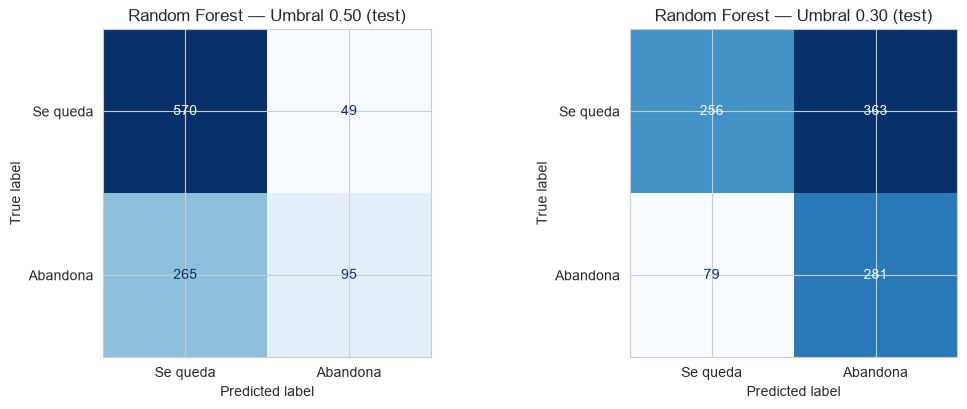

In [23]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, u, titulo in [(ejes[0], 0.5, 'Umbral 0.50'), (ejes[1], umbral_opt, f'Umbral {umbral_opt:.2f}')]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, (proba_test >= u).astype(int)),
                           display_labels=['Se queda', 'Abandona']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{mejor_nombre} — {titulo} (test)')
plt.tight_layout(); plt.show()

Con el umbral ajustado (≈0.30) el **recall pasa de 0.26 a 0.78**: el modelo detecta casi 8 de cada 10 estudiantes que abandonan, a cambio de bajar la precision de 0.66 a 0.44 (más estudiantes contactados que igual se iban a quedar). El F1 sube de 0.38 a 0.56. Para una campaña de retención de bajo costo (mail, notificación, cupón) es un intercambio conveniente; si la acción fuera cara (por ejemplo, un descuento grande) convendría un umbral más alto.

### 11.1 Curva de ganancia: ¿a quién contactar primero?
En la práctica el equipo de retención no puede contactar a todos. Ordeno a los estudiantes del test de mayor a menor riesgo y miro qué porcentaje de los que abandonan se captura contactando solo al top X%.

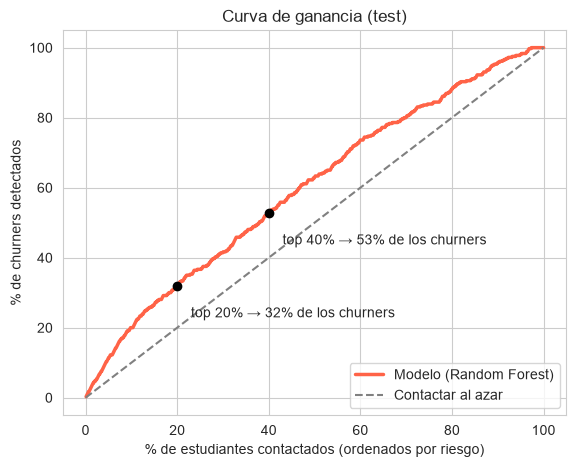

Contactando al 10% de mayor riesgo se detecta el 20.0% de los que abandonan (lift = 2.00x vs azar)
Contactando al 20% de mayor riesgo se detecta el 31.9% de los que abandonan (lift = 1.60x vs azar)
Contactando al 30% de mayor riesgo se detecta el 41.4% de los que abandonan (lift = 1.38x vs azar)
Contactando al 40% de mayor riesgo se detecta el 52.8% de los que abandonan (lift = 1.32x vs azar)


In [24]:
orden = np.argsort(-proba_test)
y_ord = y_test.values[orden]
captura = np.cumsum(y_ord) / y_ord.sum()
pct_contactado = np.arange(1, len(y_ord) + 1) / len(y_ord)

plt.figure(figsize=(6.5, 5))
plt.plot(pct_contactado * 100, captura * 100, color='tomato', lw=2.5, label=f'Modelo ({mejor_nombre})')
plt.plot([0, 100], [0, 100], ls='--', color='gray', label='Contactar al azar')
for p in [0.2, 0.4]:
    c = captura[int(p * len(y_ord)) - 1]
    plt.scatter(p * 100, c * 100, color='black', zorder=5)
    plt.annotate(f'top {int(p*100)}% → {c*100:.0f}% de los churners', (p * 100, c * 100),
                 xytext=(p * 100 + 3, c * 100 - 9))
plt.xlabel('% de estudiantes contactados (ordenados por riesgo)'); plt.ylabel('% de churners detectados')
plt.title('Curva de ganancia (test)'); plt.legend(loc='lower right'); plt.show()

for p in [0.1, 0.2, 0.3, 0.4]:
    c = captura[int(p * len(y_ord)) - 1]
    print(f'Contactando al {int(p*100):>2}% de mayor riesgo se detecta el {c*100:.1f}% de los que abandonan '
          f'(lift = {c/p:.2f}x vs azar)')

---
## 12. Interpretación del modelo con SHAP

SHAP explica cuánto empuja cada variable la predicción de cada estudiante hacia "abandona" (valores positivos) o hacia "se queda" (valores negativos). Lo calculo sobre el set de test.

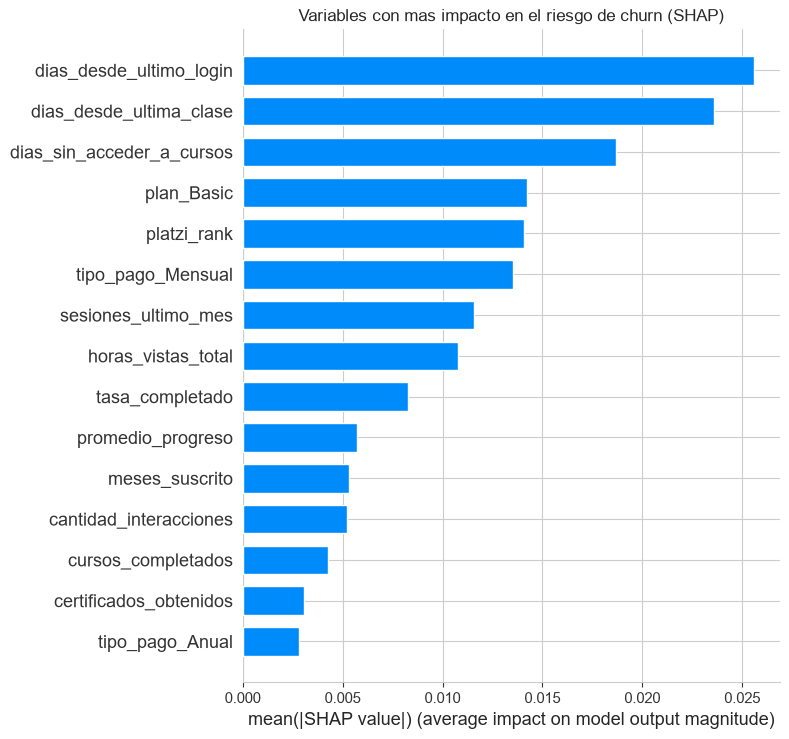

In [25]:
prep_ajustado = mejor_modelo.named_steps['prep']
estimador = mejor_modelo.named_steps['modelo']
nombres = (num_cols + list(prep_ajustado.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols)))
X_test_tr = pd.DataFrame(prep_ajustado.transform(X_test), columns=nombres, index=X_test.index)

explainer = shap.TreeExplainer(estimador)
shap_values = explainer.shap_values(X_test_tr)
if isinstance(shap_values, list):          # Random Forest devuelve una matriz por clase
    shap_values = shap_values[1]
elif np.ndim(shap_values) == 3:
    shap_values = shap_values[:, :, 1]

shap.summary_plot(shap_values, X_test_tr, plot_type='bar', max_display=15, show=False)
plt.title('Variables con mas impacto en el riesgo de churn (SHAP)'); plt.tight_layout(); plt.show()

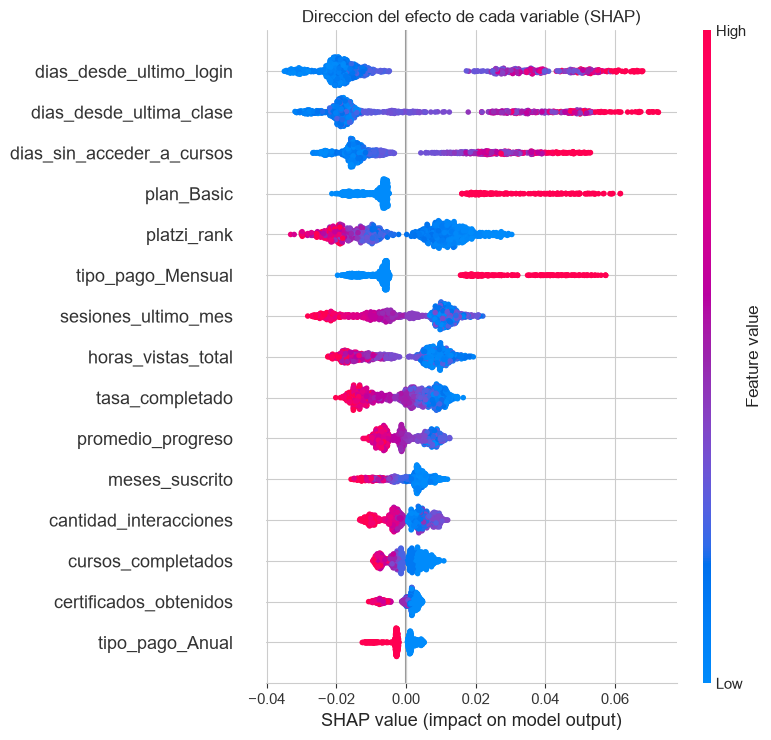

In [26]:
shap.summary_plot(shap_values, X_test_tr, max_display=15, show=False)
plt.title('Direccion del efecto de cada variable (SHAP)'); plt.tight_layout(); plt.show()

In [27]:
importancia = pd.Series(np.abs(shap_values).mean(axis=0), index=nombres).sort_values(ascending=False)
importancia.head(10).round(4)

dias_desde_ultimo_login      0.0256
dias_desde_ultima_clase      0.0236
dias_sin_acceder_a_cursos    0.0187
plan_Basic                   0.0142
platzi_rank                  0.0141
tipo_pago_Mensual            0.0135
sesiones_ultimo_mes          0.0116
horas_vistas_total           0.0108
tasa_completado              0.0083
promedio_progreso            0.0057
dtype: float64

Cómo leer el gráfico de puntos: cada punto es un estudiante; el color es el valor de la variable (rojo = alto, azul = bajo) y la posición horizontal es cuánto sube (derecha) o baja (izquierda) el riesgo de churn.

Lo que muestra SHAP es consistente con el EDA:
- **Inactividad reciente** (`dias_desde_ultimo_login`, `dias_desde_ultima_clase` y la variable nueva `dias_sin_acceder_a_cursos`): son las 3 variables más importantes. Valores altos (rojo) empujan hacia el abandono.
- **Plan y forma de pago** (`plan_Basic`, `tipo_pago_Mensual`): estar en el plan Basic / pago mensual aumenta el riesgo (54.7% de churn contra 19–32% en los planes Expert).
- **Compromiso con la comunidad** (`platzi_rank`): un ranking bajo se asocia a más churn (47% en el cuartil más bajo vs 26% en el más alto).
- **Poco uso** (`sesiones_ultimo_mes`, `horas_vistas_total`, `tasa_completado`): valores bajos aumentan el riesgo.
- Los **pagos fallidos**, aunque en el EDA suben la tasa de churn, no aparecen en el top 10: afectan a pocos estudiantes, así que en promedio su peso en el modelo es menor.

---
## 13. Conclusiones

**Problema.** Modelé el abandono de estudiantes de Platzi como un problema de **clasificación binaria** (36.8% de churn), usando 3 fuentes de datos unidas por estudiante.

**Ingeniería de atributos.** Sumé variables de recencia y antigüedad a partir de las fechas de interacciones y de registro, tendencias de uso y ratios. Todas las transformaciones (imputación con mediana/moda, One-Hot Encoding, estandarización y, en KNN, selección de variables) están dentro de un `Pipeline`, así que se re-ajustan dentro de cada fold de la validación cruzada y **no hay data leakage**. Las variables nuevas aportaron poco en AUC, pero `dias_sin_acceder_a_cursos` quedó entre las más importantes del modelo.

**Modelos y optimización.** Entrené 4 modelos (Árbol de Decisión, KNN, Random Forest y XGBoost) con **validación cruzada estratificada de 5 folds** y optimicé hiperparámetros con **GridSearchCV** (Árbol, KNN) y **RandomizedSearchCV** (Random Forest, XGBoost). Con los hiperparámetros por defecto los ensambles sobreajustaban por completo (AUC train ≈ 1.0); la optimización redujo esa brecha y mejoró el AUC de validación en todos los modelos.

**Modelo seleccionado: Random Forest optimizado.** Tiene el mayor AUC en validación cruzada (0.662 ± 0.007) y lo confirma en el test reservado (0.655), superando a los dos modelos de la entrega anterior (Árbol 0.630 y KNN 0.592 en test). Con el **umbral ajustado a ≈0.30** detecta el **78%** de los estudiantes que van a abandonar. Si solo se puede contactar a una parte, el **10% de mayor riesgo concentra el 20% de los churners (el doble que al azar)** y el 40% de mayor riesgo concentra el 53%.

**Respuestas a las preguntas:**
1. *¿Se puede predecir el churn?* Sí, en forma moderada (AUC ≈ 0.66): no es un modelo para decidir caso por caso con certeza, pero **sí sirve para priorizar** a quién contactar.
2. *¿Qué pesa más?* La inactividad reciente (días sin entrar / sin avanzar cursos), el plan Basic / pago mensual, el bajo ranking en la comunidad y el bajo uso.
3. *¿Los ensambles mejoran a los modelos simples?* Sí respecto al Árbol (0.662 vs 0.633 en CV). KNN, una vez bien optimizado (200 vecinos, 15 variables), queda casi empatado con los ensambles: la mayor ganancia vino de **optimizar hiperparámetros**, más que del tipo de modelo.

**Recomendaciones de negocio:**
- Disparar una alerta automática cuando un estudiante supera ~2 semanas sin entrar o sin avanzar un curso.
- Priorizar a los planes **mensuales / Basic** con ofertas de pase a plan anual.
- Fomentar la participación en la comunidad (foro, ranking) en los primeros meses.
- Avisar y ofrecer medios de pago alternativos ante el **primer pago fallido** (en el EDA cada intento fallido sube la tasa de churn).

**Limitaciones y próximos pasos:**
- El AUC de ≈0.65 indica que falta información relevante (por ejemplo, motivo de cancelación, interacción con soporte/marketing, precio pagado). Sumar esas fuentes probablemente mejore más que seguir ajustando modelos.
- Validar el modelo en el tiempo (entrenar con meses anteriores y predecir meses futuros) antes de usarlo en producción.
- Medir el impacto real con un experimento A/B: contactar a una parte de los estudiantes de alto riesgo y comparar su churn contra un grupo control.